# PV Project- Exploartion with Base tables & views

### Import Libraries

In [29]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

### Establish the DB connection

In [30]:
# Establishing connection wit the database

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DB_PATH = PROJECT_ROOT / "data" / "faers_db.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=True) # read_only=True for exploration, and read_only=False only when creating tables.

### Identify the Tables

In [31]:
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 50)
print(con.sql("SHOW TABLES").df())

                     name
0               case_base
1               case_drug
2           case_exposure
3              case_month
4            case_outcome
5                 case_pt
6             case_source
7              clean_demo
8                 demo_us
9             drug_detail
10               exposure
11             faers_flat
12                    m_N
13                   m_ev
14                  m_grp
15                 m_pair
16                 months
17            pair_counts
18              pair_grid
19             pair_month
20                ps_case
21          ps_case_event
22                ps_drug
23               raw_demo
24               raw_indi
25               raw_reac
26               raw_ther
27               ref_drug
28       ref_known_signal
29          signal_labels
30              signal_ts
31       study_case_event
32            study_cases
33        study_drug_rows
34   v_ingredient_summary
35   v_known_signal_check
36  v_known_signal_family
37        v_

### Explore the Tables

In [32]:
# Exploring the tables
case_base= con.sql("SELECT * FROM case_base").df()
cases = con.sql("SELECT * FROM ps_case").df()          # one row per case x ingredient
ce    = con.sql("SELECT * FROM ps_case_event").df()    # one row per case x ingredient x event
drugs = con.sql("SELECT * FROM ps_drug").df()          # drug level: brand, indication, onset
sig   = con.sql("SELECT * FROM v_signals").df()        # flagged pairs
stats = con.sql("SELECT * FROM v_pair_stats").df()     # all pairs with metrics
ps_case_event= con.sql("SELECT * FROM ps_case_event").df()
case_month= con.sql("SELECT * FROM case_month").df()
case_exposure= con.sql("SELECT * FROM case_exposure").df()
drug_detail = con.sql("SELECT * FROM drug_detail").df()
clean_demo= con.sql("SELECT * FROM clean_demo").df()
faers_flat = con.sql("SELECT * FROM faers_flat").df()  # comprehensive table

In [ ]:
drug_detail

In [38]:
unique_list = drug_detail["indications"].drop_duplicates().tolist()
unique_list

[array(['TYPE 2 DIABETES MELLITUS'], dtype=object),
 array(['WEIGHT DECREASED'], dtype=object),
 array(['PRODUCT USED FOR UNKNOWN INDICATION'], dtype=object),
 array(['INSULIN RESISTANCE'], dtype=object),
 array(['DIABETES MELLITUS'], dtype=object),
 array(['BLOOD GLUCOSE INCREASED'], dtype=object),
 array(['OBESITY'], dtype=object),
 array(['TYPE 1 DIABETES MELLITUS'], dtype=object),
 array(['DIABETES MELLITUS MANAGEMENT'], dtype=object),
 array(['BLOOD GLUCOSE ABNORMAL'], dtype=object),
 array(['INCREASED APPETITE'], dtype=object),
 array(['WEIGHT CONTROL'], dtype=object),
 array(['BLOOD GLUCOSE'], dtype=object),
 array(['DIABETES MELLITUS INADEQUATE CONTROL'], dtype=object),
 array(['HORMONE THERAPY'], dtype=object),
 array(['CARDIAC FAILURE CHRONIC'], dtype=object),
 array(['CARDIAC FAILURE'], dtype=object),
 array(['PROPHYLAXIS'], dtype=object),
 array(['OVERWEIGHT'], dtype=object),
 array(['HYPERGLYCAEMIA'], dtype=object),
 array(['WEIGHT INCREASED'], dtype=object),
 array(['GLUC

In [19]:
print(ce.shape, ce.caseid.nunique(), "cases")

(155068, 21) 67653 cases


#### ps_case_event

In [6]:
ps_case_event.head(15)

,ingredient,drug_class,pt,caseid,init_month,init_year,age_years,sex,occp_cod,rept_cod,event_dt_parsed,has_outcome,serious_core,death,life_threat,hospitalised,disability,src_literature,src_health_prof,dual_class,has_combo
0,empagliflozin,SGLT2i,BACK PAIN,15700473,2018-12-01,2018,52.0,F,OT,PER,NaT,False,False,False,False,False,False,False,False,False,False
1,canagliflozin,SGLT2i,ABDOMINAL DISCOMFORT,14721001,2018-04-01,2018,NaN,F,CN,PER,NaT,False,False,False,False,False,False,False,False,False,False
2,canagliflozin,SGLT2i,COMA,12885990,2016-10-01,2016,41.0,F,CN,EXP,2015-07-10,True,True,False,True,True,False,False,False,False,False
3,dulaglutide,GLP1RA,DIARRHOEA,13894910,2017-08-01,2017,NaN,M,CN,PER,NaT,False,False,False,False,False,False,False,False,False,False
4,dulaglutide,GLP1RA,HALLUCINATION,13614307,2017-06-01,2017,NaN,M,CN,PER,NaT,False,False,False,False,False,False,False,False,False,False
5,dulaglutide,GLP1RA,INJECTION SITE HAEMORRHAGE,15987510,2019-02-01,2019,NaN,F,CN,PER,NaT,False,False,False,False,False,False,False,False,False,False
6,canagliflozin,SGLT2i,FUNGAL INFECTION,11187848,2015-06-01,2015,NaN,F,OT,PER,NaT,False,False,False,False,False,False,False,False,False,False
7,liraglutide,GLP1RA,BLADDER MASS,10261588,2014-06-01,2014,70.0,None,CN,EXP,NaT,True,False,False,False,False,False,False,False,False,False
8,dapagliflozin,SGLT2i,HAEMATURIA,10977100,2015-04-01,2015,NaN,M,MD,PER,NaT,False,False,False,False,False,False,False,False,False,False
9,dulaglutide,GLP1RA,DIARRHOEA,13240574,2017-02-01,2017,NaN,F,CN,PER,2017-01-28,False,False,False,False,False,False,False,False,False,False


In [10]:
# Importing the  df (ps_event)
# 1. Define the target directory and ensure it exists
results_dir = Path.home() / "Desktop" / "Final Project" / "Results"
results_dir.mkdir(parents=True, exist_ok=True)  # Creates the folder if it doesn't exist

# 2. Define the full file path for the CSV
output_file = results_dir / "ps_case_event.csv"

# 3. Export the DataFrame to CSV
ps_case_event.to_csv(output_file, index=False)

print(f"Successfully saved DataFrame to: {output_file}")

Successfully saved DataFrame to: /Users/shymashameer/Desktop/Final Project/Results/ps_case_event.csv


#### faers_flat

In [22]:
faers_flat.head()

,caseid,primaryid,init_month,init_year,country,age_years,sex,occp_cod,rept_cod,ingredient,drug_class,brand,indication_group,indications,drug_start,event_dt,days_to_onset,dechal,rechal,event,has_outcome,serious_core,death,life_threat,hospitalised,disability,congenital,intervention,other_serious,src_literature,src_health_prof,dual_class
0,16420567,164205671,2019-06-01,2019,US,62.0,F,CN,EXP,semaglutide,GLP1RA,OZEMPIC,obesity/weight,WEIGHT DECREASED,2019-04-07,NaT,<NA>,Y,N,LYME DISEASE,True,False,False,False,False,False,False,False,True,False,False,False
1,16423035,164230351,2019-06-01,2019,US,NaN,M,MD,PER,empagliflozin,SGLT2i,JARDIANCE,diabetes/other,CARDIAC DEATH,NaT,NaT,<NA>,U,None,FUNGAL INFECTION,False,False,False,False,False,False,False,False,False,False,False,False
2,16423833,164238331,2019-06-01,2019,US,NaN,F,CN,EXP,dulaglutide,GLP1RA,TRULICITY,diabetes/other,PRODUCT USED FOR UNKNOWN INDICATION,NaT,NaT,<NA>,U,U,NAUSEA,False,False,False,False,False,False,False,False,False,False,False,False
3,16429476,164294761,2019-06-01,2019,US,NaN,F,CN,EXP,dulaglutide,GLP1RA,TRULICITY,diabetes/other,TYPE 2 DIABETES MELLITUS,NaT,NaT,<NA>,U,U,INJECTION SITE PRURITUS,False,False,False,False,False,False,False,False,False,False,False,False
4,16443694,164436941,2019-06-01,2019,US,NaN,None,CN,EXP,dulaglutide,GLP1RA,TRULICITY,diabetes/other,DIABETES MELLITUS,NaT,NaT,<NA>,U,U,FATIGUE,False,False,False,False,False,False,False,False,False,False,False,False


In [23]:
# Importing the  df (faers_flat)
# 1. Define the target directory and ensure it exists
results_dir = Path.home() / "Desktop" / "Final Project" / "Results"
results_dir.mkdir(parents=True, exist_ok=True)  # Creates the folder if it doesn't exist

# 2. Define the full file path for the CSV
output_file = results_dir / "faers_flat.csv"

# 3. Export the DataFrame to CSV
faers_flat.to_csv(output_file, index=False)

print(f"Successfully saved DataFrame to: {output_file}")

Successfully saved DataFrame to: /Users/shymashameer/Desktop/Final Project/Results/faers_flat.csv


In [24]:
faers_flat.groupby("ingredient").caseid.nunique()   

ingredient
canagliflozin    18865
dapagliflozin     4851
dulaglutide      23381
empagliflozin     6407
ertugliflozin      358
liraglutide      11604
semaglutide       2187
Name: caseid, dtype: int64

In [25]:
faers_flat[(faers_flat.ingredient == "liraglutide") & (faers_flat.indication_group == "obesity/weight")].event.value_counts().head(10)


event
NAUSEA              415
VOMITING            177
OFF LABEL USE       163
DIARRHOEA           115
WEIGHT LOSS POOR    101
DRUG INEFFECTIVE     99
HEADACHE             98
FATIGUE              91
CONSTIPATION         85
WEIGHT INCREASED     74
Name: count, dtype: int64

In [26]:
faers_flat.groupby("ingredient")[["serious_core", "death"]].mean().round(3)

,serious_core,death
ingredient,,
canagliflozin,0.490,0.018
dapagliflozin,0.240,0.018
dulaglutide,0.082,0.005
empagliflozin,0.236,0.012
ertugliflozin,0.147,0.000
liraglutide,0.158,0.019
semaglutide,0.169,0.007


#### clean_demo

In [ ]:
clean_demo


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155068 entries, 0 to 155067
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   ingredient       155068 non-null  object        
 1   drug_class       155068 non-null  object        
 2   pt               155068 non-null  object        
 3   caseid           155068 non-null  object        
 4   init_month       155068 non-null  datetime64[us]
 5   init_year        155068 non-null  int64         
 6   age_years        85862 non-null   float64       
 7   sex              145757 non-null  object        
 8   occp_cod         150215 non-null  object        
 9   rept_cod         155068 non-null  object        
 10  event_dt_parsed  47116 non-null   datetime64[us]
 11  has_outcome      155068 non-null  bool          
 12  serious_core     155068 non-null  bool          
 13  death            155068 non-null  bool          
 14  life_threat      155

### Top events per drug, with seriousness

In [ ]:
# canagliflozin
def top_events(ing, n=15):
    d = ce[ce.ingredient == ing]
    n_cases = d.caseid.nunique()
    t = (d.groupby("pt")
           .agg(cases=("caseid", "nunique"),
                serious=("serious_core", "sum"),
                deaths=("death", "sum"),
                hospitalised=("hospitalised", "sum"),
                life_threat=("life_threat", "sum"))
           .assign(non_serious=lambda x: x.cases - x.serious,
                   pct_of_drug_cases=lambda x: (100 * x.cases / n_cases).round(1),
                   pct_serious=lambda x: (100 * x.serious / x.cases).round(1))
           .sort_values("cases", ascending=False).head(n))
    return t[["cases", "pct_of_drug_cases", "serious", "non_serious", "pct_serious",
              "deaths", "hospitalised", "life_threat"]]

top_events("canagliflozin")

,cases,pct_of_drug_cases,serious,non_serious,pct_serious,deaths,hospitalised,life_threat
pt,,,,,,,,
DIABETIC KETOACIDOSIS,2589,13.7,2220,369,85.7,45,2201,184
TOE AMPUTATION,1915,10.2,1446,469,75.5,15,1425,3
OSTEOMYELITIS,1894,10.0,1602,292,84.6,16,1584,6
ACUTE KIDNEY INJURY,1622,8.6,1420,202,87.5,57,1410,87
FUNGAL INFECTION,1315,7.0,68,1247,5.2,1,55,11
GANGRENE,913,4.8,831,82,91.0,11,807,4
CELLULITIS,867,4.6,774,93,89.3,7,765,0
WEIGHT DECREASED,852,4.5,119,733,14.0,8,106,16
URINARY TRACT INFECTION,797,4.2,263,534,33.0,12,251,12


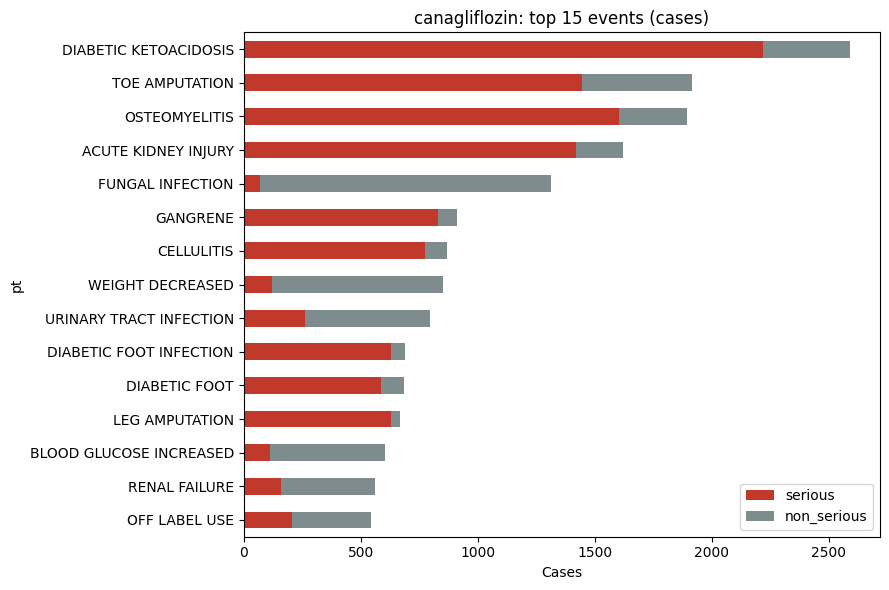

In [27]:
ing = "canagliflozin"
d = (ce[ce.ingredient == ing].groupby("pt")
       .agg(serious=("serious_core", "sum"), cases=("caseid", "nunique"))
       .assign(non_serious=lambda x: x.cases - x.serious)
       .sort_values("cases", ascending=False).head(15).iloc[::-1])
d[["serious", "non_serious"]].plot.barh(stacked=True, figsize=(9, 6),
        color=["#c0392b", "#7f8c8d"], title=f"{ing}: top 15 events (cases)")
plt.xlabel("Cases"); plt.tight_layout(); plt.show()

In [14]:
# dapagliflozin
def top_events(ing, n=15):
    d = ce[ce.ingredient == ing]
    n_cases = d.caseid.nunique()
    t = (d.groupby("pt")
           .agg(cases=("caseid", "nunique"),
                serious=("serious_core", "sum"),
                deaths=("death", "sum"),
                hospitalised=("hospitalised", "sum"),
                life_threat=("life_threat", "sum"))
           .assign(non_serious=lambda x: x.cases - x.serious,
                   pct_of_drug_cases=lambda x: (100 * x.cases / n_cases).round(1),
                   pct_serious=lambda x: (100 * x.serious / x.cases).round(1))
           .sort_values("cases", ascending=False).head(n))
    return t[["cases", "pct_of_drug_cases", "serious", "non_serious", "pct_serious",
              "deaths", "hospitalised", "life_threat"]]

top_events("dapagliflozin")

,cases,pct_of_drug_cases,serious,non_serious,pct_serious,deaths,hospitalised,life_threat
pt,,,,,,,,
FUNGAL INFECTION,631,13.0,31,600,4.9,2,29,5
WEIGHT DECREASED,380,7.8,31,349,8.2,3,28,6
DIABETIC KETOACIDOSIS,374,7.7,295,79,78.9,6,290,51
BLOOD GLUCOSE INCREASED,328,6.8,39,289,11.9,0,35,11
URINARY TRACT INFECTION,240,4.9,78,162,32.5,2,71,10
POLLAKIURIA,184,3.8,13,171,7.1,1,9,1
NAUSEA,175,3.6,41,134,23.4,0,39,13
DIZZINESS,171,3.5,16,155,9.4,0,14,2
DEHYDRATION,149,3.1,61,88,40.9,0,61,10


Important caveat: serious_core is a case-level flag (from OUTC), not an event-level one. A case with a serious outcome marks every event on it as serious, so “serious” here means “events reported on serious cases”. 

### Events by drug comparison

In [12]:
wide = (ce.groupby(["pt", "ingredient"]).caseid.nunique().unstack(fill_value=0))
wide["total"] = wide.sum(axis=1)
display(wide.sort_values("total", ascending=False).head(30))

# Share of each drug's cases (comparable across drugs of different size)
share = (wide.drop(columns="total") / ce.groupby("ingredient").caseid.nunique() * 100).round(1)
display(share.loc[wide.sort_values("total", ascending=False).head(30).index])

ingredient,canagliflozin,dapagliflozin,dulaglutide,empagliflozin,ertugliflozin,liraglutide,semaglutide,total
pt,,,,,,,,
NAUSEA,423,175,3782,207,33,2058,508,7186
BLOOD GLUCOSE INCREASED,602,328,2930,323,10,858,174,5225
DIABETIC KETOACIDOSIS,2589,374,73,482,14,32,18,3582
DIARRHOEA,264,119,1777,156,12,791,240,3359
VOMITING,225,96,1583,136,17,960,304,3321
WEIGHT DECREASED,852,380,1016,411,7,373,131,3170
INJECTION SITE PAIN,0,25,2928,5,0,182,20,3160
FUNGAL INFECTION,1315,631,47,625,52,28,5,2703
PANCREATITIS,230,56,653,58,0,1109,87,2193


ingredient,canagliflozin,dapagliflozin,dulaglutide,empagliflozin,ertugliflozin,liraglutide,semaglutide
pt,,,,,,,
NAUSEA,2.2,3.6,16.2,3.2,9.2,17.7,23.2
BLOOD GLUCOSE INCREASED,3.2,6.8,12.5,5.0,2.8,7.4,8.0
DIABETIC KETOACIDOSIS,13.7,7.7,0.3,7.5,3.9,0.3,0.8
DIARRHOEA,1.4,2.5,7.6,2.4,3.4,6.8,11.0
VOMITING,1.2,2.0,6.8,2.1,4.7,8.3,13.9
WEIGHT DECREASED,4.5,7.8,4.3,6.4,2.0,3.2,6.0
INJECTION SITE PAIN,0.0,0.5,12.5,0.1,0.0,1.6,0.9
FUNGAL INFECTION,7.0,13.0,0.2,9.8,14.5,0.2,0.2
PANCREATITIS,1.2,1.2,2.8,0.9,0.0,9.6,4.0


### Serious vs Non serious profile

In [13]:
# Overall seriousness by drug, one row per case
c = ce.drop_duplicates(["caseid", "ingredient"])
display(c.groupby("ingredient").agg(cases=("caseid", "size"),
        has_outcome=("has_outcome", "mean"), serious=("serious_core", "mean"),
        death=("death", "mean"), hosp=("hospitalised", "mean")).round(3))

# Events most concentrated in serious cases (min 30 cases)
sev = (ce.groupby(["ingredient", "pt"])
         .agg(cases=("caseid", "nunique"), pct_serious=("serious_core", "mean"))
         .query("cases >= 30").reset_index())
display(sev.sort_values("pct_serious", ascending=False).groupby("ingredient").head(5))

,cases,has_outcome,serious,death,hosp
ingredient,,,,,
canagliflozin,18865,0.609,0.378,0.014,0.360
dapagliflozin,4851,0.310,0.192,0.018,0.167
dulaglutide,23381,0.135,0.061,0.005,0.052
empagliflozin,6407,0.285,0.188,0.011,0.169
ertugliflozin,358,0.173,0.120,0.000,0.112
liraglutide,11604,0.324,0.158,0.029,0.131
semaglutide,2187,0.325,0.134,0.005,0.125


,ingredient,pt,cases,pct_serious
9,canagliflozin,ACUTE RESPIRATORY FAILURE,51,1.000000
113,canagliflozin,METABOLIC ENCEPHALOPATHY,43,1.000000
157,canagliflozin,RESPIRATORY FAILURE,34,1.000000
311,dulaglutide,DEATH,74,1.000000
39,canagliflozin,DEATH,73,1.000000
159,canagliflozin,SEPTIC SHOCK,82,1.000000
210,dapagliflozin,DEATH,47,1.000000
601,liraglutide,HOSPITALISATION,33,0.969697
260,dapagliflozin,SEPSIS,46,0.934783
258,dapagliflozin,RENAL INJURY,32,0.906250


### Summary

1. DEMOGRAPHIC SUMMARY


,cohort,total_cases,mean_age,median_age,pct_female,pct_male,pct_sex_missing,pct_age_missing,pct_serious
0,GLP1RA,37007,59.2,60.0,58.1,37.0,4.9,56.0,9.4
1,SGLT2i,30259,57.4,58.0,44.1,42.4,13.5,50.7,30.3


,ingredient,drug_class,ps_cases,median_age,pct_female,pct_serious,pct_death
0,dulaglutide,GLP1RA,23381,60.0,58.4,6.1,0.5
1,liraglutide,GLP1RA,11604,60.0,67.5,15.8,2.9
2,semaglutide,GLP1RA,2187,62.0,55.2,13.4,0.5
3,canagliflozin,SGLT2i,18865,57.0,49.3,37.8,1.4
4,empagliflozin,SGLT2i,6407,61.0,50.7,18.8,1.1
5,dapagliflozin,SGLT2i,4851,58.9,57.3,19.2,1.8
6,ertugliflozin,SGLT2i,358,56.0,54.8,12.0,0.0


2. TEMPORAL REPORTING TRENDS (2014-2019, by FDA first-receipt year)


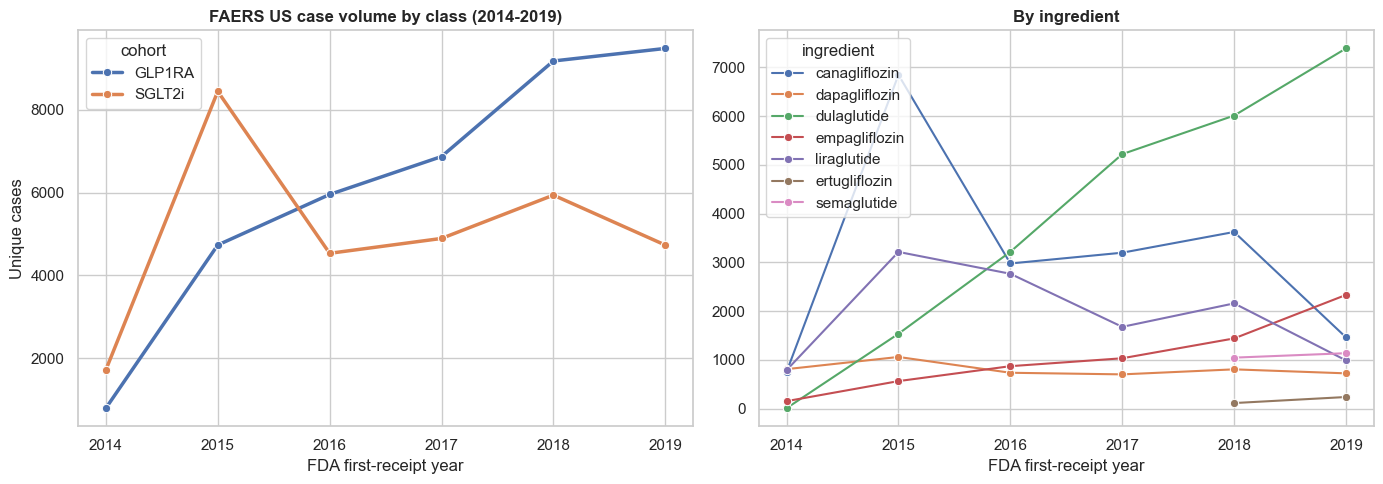

3. DISPROPORTIONALITY: ACTIVE COMPARATOR (class vs class)

Events disproportionately reported with SGLT2i (vs GLP-1RA)


,adverse_event,SGLT2i_cases,GLP1RA_cases,PRR,ROR,95% CI,zero_cell
262,TOE AMPUTATION,1948,1,2382.42,2546.28,[358.46 - 18087.06],False
392,OSTEOMYELITIS,1901,6,387.49,413.40,[185.46 - 921.49],False
150,GANGRENE,938,2,573.59,591.91,[147.80 - 2370.47],False
305,LEG AMPUTATION,676,1,826.75,845.62,[118.93 - 6012.42],False
600,DIABETIC FOOT INFECTION,689,0,1686.52,1725.82,[107.83 - 27621.86],True
304,DIABETIC FOOT,680,2,415.82,425.36,[106.15 - 1704.43],False
347,FOOT AMPUTATION,523,0,1280.48,1303.01,[81.39 - 20861.35],True
215,AMPUTATION,286,0,700.78,707.47,[44.14 - 11339.08],True
550,GENITAL INFECTION FUNGAL,314,3,128.01,129.34,[41.49 - 403.25],False
40,FUNGAL INFECTION,2618,68,47.09,51.45,[40.42 - 65.49],False



Events disproportionately reported with GLP-1RA (vs SGLT2i)


,adverse_event,GLP1RA_cases,SGLT2i_cases,PRR,ROR,95% CI,zero_cell
74,ACCIDENTAL UNDERDOSE,712,0,1165.17,1188.02,[74.23 - 19013.73],True
536,INJECTION SITE PAIN,3126,30,85.20,92.97,[64.87 - 133.24],False
156,INJECTION SITE BRUISING,876,10,71.63,73.34,[39.31 - 136.81],False
112,INJECTION SITE ERYTHEMA,744,10,60.83,62.06,[33.25 - 115.85],False
189,ACCIDENTAL OVERDOSE,523,7,61.09,61.95,[29.38 - 130.62],False
318,INJECTION SITE RASH,331,3,90.21,91.02,[29.20 - 283.70],False
163,INJECTION SITE HAEMORRHAGE,1212,26,38.12,39.37,[26.69 - 58.08],False
499,INAPPROPRIATE SCHEDULE OF PRODUCT ADMINISTRATION,545,9,49.51,50.24,[26.00 - 97.09],False
429,INJECTION SITE URTICARIA,252,0,412.92,415.75,[25.93 - 6665.66],True
385,INJECTION SITE PRURITUS,606,13,38.12,38.73,[22.36 - 67.11],False



Most frequent SGLT2i events with their comparator counts


,adverse_event,SGLT2i_cases,GLP1RA_cases,PRR,ROR,95% CI
42,DIABETIC KETOACIDOSIS,3388,97,42.72,47.98,[39.18 - 58.74]
40,FUNGAL INFECTION,2618,68,47.09,51.45,[40.42 - 65.49]
262,TOE AMPUTATION,1948,1,2382.42,2546.28,[358.46 - 18087.06]
392,OSTEOMYELITIS,1901,6,387.49,413.40,[185.46 - 921.49]
456,ACUTE KIDNEY INJURY,1758,137,15.69,16.60,[13.94 - 19.77]
518,WEIGHT DECREASED,1632,1502,1.33,1.35,[1.25 - 1.45]
226,URINARY TRACT INFECTION,1282,141,11.12,11.57,[9.71 - 13.77]
73,BLOOD GLUCOSE INCREASED,1241,3939,0.39,0.36,[0.34 - 0.38]
182,DIZZINESS,1093,929,1.44,1.46,[1.33 - 1.59]
150,GANGRENE,938,2,573.59,591.91,[147.80 - 2370.47]


4. FULL-BACKGROUND SIGNALS (all US cases as comparator)


,ingredient,pt,a,prr,ror_lo,ic025,status,onset,pct_serious
0,canagliflozin,TOE AMPUTATION,1915,763.95,779.01,7.55,emerging,2016-06-01,75.5
1,canagliflozin,DIABETIC FOOT INFECTION,688,1383.99,1197.61,7.53,emerging,2017-09-01,91.4
2,canagliflozin,FOOT AMPUTATION,517,819.22,710.18,7.31,emerging,2016-09-01,85.3
3,canagliflozin,LIMB AMPUTATION,233,6608.77,3552.65,7.21,emerging,2017-07-01,85.0
4,canagliflozin,DIABETIC FOOT,683,466.81,428.32,7.17,emerging,2017-04-01,85.7
5,canagliflozin,OSTEOMYELITIS ACUTE,231,2047.51,1431.84,7.13,emerging,2017-11-01,84.0
6,canagliflozin,DIABETIC KETOACIDOSIS,2589,246.75,270.58,6.95,pre-existing,2014-02-01,85.7
7,canagliflozin,GANGRENE,913,272.02,260.69,6.91,emerging,2016-11-01,91.0
8,canagliflozin,AMPUTATION,285,495.93,415.14,6.91,emerging,2017-06-01,60.4
9,canagliflozin,LEG AMPUTATION,668,286.64,266.57,6.89,emerging,2016-12-01,94.3


In [ ]:

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60, "display.width", 220)


# Shared cohort definition: PS, non-combo, one class only (dual-class cases removed)
COHORT_CTE = """
cohort AS (
    SELECT caseid, init_year, init_month, age_years, sex, serious_core,
           CASE WHEN ps_class_sglt2i THEN 'SGLT2i' ELSE 'GLP1RA' END AS cohort
    FROM study_cases
    WHERE ps_class_sglt2i <> ps_class_glp1ra
      AND NOT dual_class
)"""

# ------------------------------------------------------------
print("1. DEMOGRAPHIC SUMMARY")
# ------------------------------------------------------------
df_demo = con.sql(f"""
WITH {COHORT_CTE}
SELECT cohort,
       COUNT(*)                                                    AS total_cases,
       ROUND(AVG(age_years), 1)                                    AS mean_age,
       ROUND(MEDIAN(age_years), 1)                                 AS median_age,
       ROUND(100.0 * COUNT(*) FILTER (WHERE upper(sex)='F') / COUNT(*), 1) AS pct_female,
       ROUND(100.0 * COUNT(*) FILTER (WHERE upper(sex)='M') / COUNT(*), 1) AS pct_male,
       ROUND(100.0 * COUNT(*) FILTER (WHERE sex IS NULL OR upper(sex) NOT IN ('F','M')) / COUNT(*), 1) AS pct_sex_missing,
       ROUND(100.0 * COUNT(*) FILTER (WHERE age_years IS NULL) / COUNT(*), 1) AS pct_age_missing,
       ROUND(100.0 * AVG(serious_core::INT), 1)                    AS pct_serious
FROM cohort GROUP BY cohort ORDER BY cohort
""").df()
display(df_demo)

# Same summary by ingredient
display(con.sql("""
SELECT ingredient, drug_class, ps_cases, median_age, pct_female, pct_serious, pct_death
FROM v_ingredient_summary ORDER BY drug_class, ps_cases DESC""").df())

# ------------------------------------------------------------
print("2. TEMPORAL REPORTING TRENDS (2014-2019, by FDA first-receipt year)")
# ------------------------------------------------------------
df_trends = con.sql(f"""
WITH {COHORT_CTE}
SELECT init_year AS report_year, cohort, COUNT(*) AS case_count
FROM cohort GROUP BY ALL ORDER BY report_year, cohort
""").df()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=df_trends, x="report_year", y="case_count", hue="cohort",
             marker="o", linewidth=2.5, ax=ax[0])
ax[0].set_title("FAERS US case volume by class (2014-2019)", fontweight="bold")
ax[0].set_xlabel("FDA first-receipt year"); ax[0].set_ylabel("Unique cases")
ax[0].set_xticks(range(2014, 2020))

df_ing = con.sql("""SELECT init_year AS report_year, ingredient, COUNT(*) AS case_count
                    FROM ps_case GROUP BY ALL ORDER BY 1, 2""").df()
sns.lineplot(data=df_ing, x="report_year", y="case_count", hue="ingredient",
             marker="o", ax=ax[1])
ax[1].set_title("By ingredient", fontweight="bold")
ax[1].set_xlabel("FDA first-receipt year"); ax[1].set_ylabel("")
ax[1].set_xticks(range(2014, 2020))
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
print("3. DISPROPORTIONALITY: ACTIVE COMPARATOR (class vs class)")
# ------------------------------------------------------------
def active_comparator(con, exposed="SGLT2i", reference="GLP1RA", min_a=10):
    """2x2 per event: exposed class vs the other class. Returns PRR, ROR and 95% CI."""
    df = con.sql(f"""
    WITH {COHORT_CTE},
    tot AS (SELECT cohort, COUNT(*) AS n FROM cohort GROUP BY 1),
    ev  AS (SELECT c.cohort, p.pt, COUNT(*) AS n
            FROM cohort c JOIN case_pt p USING (caseid) GROUP BY 1, 2)
    SELECT e.pt AS adverse_event,
           e.n                               AS a,
           te.n - e.n                        AS b,
           COALESCE(r.n, 0)                  AS c,
           tr.n - COALESCE(r.n, 0)           AS d,
           te.n AS total_exposed, tr.n AS total_reference
    FROM ev e
    JOIN tot te ON te.cohort = '{exposed}'
    JOIN tot tr ON tr.cohort = '{reference}'
    LEFT JOIN ev r ON r.pt = e.pt AND r.cohort = '{reference}'
    WHERE e.cohort = '{exposed}' AND e.n >= {min_a}
    """).df()

    df["zero_cell"] = (df.c == 0)
    # Haldane-Anscombe correction only where a cell is zero
    k = np.where(df.zero_cell, 0.5, 0.0)
    a, b, c, d = df.a + k, df.b + k, df.c + k, df.d + k
    df["PRR"]  = (a / (a + b)) / (c / (c + d))
    df["ROR"]  = (a * d) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    df["ROR_lo"] = np.exp(np.log(df.ROR) - 1.96 * se)
    df["ROR_hi"] = np.exp(np.log(df.ROR) + 1.96 * se)
    df["95% CI"] = df.apply(lambda r: f"[{r.ROR_lo:.2f} - {r.ROR_hi:.2f}]", axis=1)
    return df

def show(df, exposed, reference, n=20):
    out = df.rename(columns={"a": f"{exposed}_cases", "c": f"{reference}_cases"})
    cols = ["adverse_event", f"{exposed}_cases", f"{reference}_cases", "PRR", "ROR", "95% CI", "zero_cell"]
    return out.sort_values("ROR_lo", ascending=False).head(n)[cols].round({"PRR": 2, "ROR": 2})

sg = active_comparator(con, "SGLT2i", "GLP1RA")
gl = active_comparator(con, "GLP1RA", "SGLT2i")

print("\nEvents disproportionately reported with SGLT2i (vs GLP-1RA)")
display(show(sg, "SGLT2i", "GLP1RA"))
print("\nEvents disproportionately reported with GLP-1RA (vs SGLT2i)")
display(show(gl, "GLP1RA", "SGLT2i"))

# Most frequent events, as in the original output
print("\nMost frequent SGLT2i events with their comparator counts")
display(sg.sort_values("a", ascending=False).head(20)
          .rename(columns={"a": "SGLT2i_cases", "c": "GLP1RA_cases"})
          [["adverse_event", "SGLT2i_cases", "GLP1RA_cases", "PRR", "ROR", "95% CI"]].round(2))

# ------------------------------------------------------------
print("4. FULL-BACKGROUND SIGNALS (all US cases with selected drugs as comparator)")
# ------------------------------------------------------------
display(con.sql("""
SELECT ingredient, pt, a, round(prr,2) prr, round(ror_lo,2) ror_lo, round(ic025,2) ic025,
       status, onset, pct_serious
FROM v_signals ORDER BY ic025 DESC LIMIT 30""").df())

### Closing the connection

In [28]:
con.close()

# Explicitly close any ambient DuckDB connections
try:
    duckdb.close()
    print("✓ Closed ambient DuckDB connection.")
except Exception as e:
    print(f"Notice: {e}")

✓ Closed ambient DuckDB connection.
